In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from torchvision import transforms
from torch.utils.data import DataLoader

from transformers import CLIPModel
from medmnist import INFO
from medmnist import BloodMNIST

from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

from torch.cuda.amp import autocast, GradScaler

In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)
print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: NVIDIA GeForce GTX 1650


In [3]:
# Changed from pathmnist to bloodmnist
data_flag = "bloodmnist"
info = INFO[data_flag]
DataClass = getattr(__import__("medmnist"), info["python_class"])

train_dataset = DataClass(split="train", download=True)
val_dataset = DataClass(split="val", download=True)
test_dataset = DataClass(split="test", download=True)

# BloodMNIST has 8 classes
num_classes = len(info["label"])
print(f"Number of classes: {num_classes}")
print(f"Class labels: {info['label']}")


00%|██████████████████████████████████████████████████████████████████████████████| 35.5M/35.5M [02:13<00:00, 266kB/s]

Using downloaded and verified file: C:\Users\Acer\.medmnist\bloodmnist.npz
Using downloaded and verified file: C:\Users\Acer\.medmnist\bloodmnist.npz
Number of classes: 8
Class labels: {'0': 'basophil', '1': 'eosinophil', '2': 'erythroblast', '3': 'immature granulocytes(myelocytes, metamyelocytes and promyelocytes)', '4': 'lymphocyte', '5': 'monocyte', '6': 'neutrophil', '7': 'platelet'}


In [4]:
# Same CLIP normalization values — keep identical to PathMNIST version
transform = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.48145466, 0.4578275, 0.40821073],
        std=[0.26862954, 0.26130258, 0.27577711]
    )
])

train_dataset.transform = transform
val_dataset.transform = transform
test_dataset.transform = transform

In [5]:
batch_size = 32

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size)
test_loader = DataLoader(test_dataset, batch_size=batch_size)

In [6]:
# Same CLIP model — no change needed here
clip_model = CLIPModel.from_pretrained(
    "openai/clip-vit-base-patch32",
    use_safetensors=True
)

clip_model = clip_model.to(device)

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

CLIPModel LOAD REPORT from: openai/clip-vit-base-patch32
Key                                  | Status     |  | 
-------------------------------------+------------+--+-
vision_model.embeddings.position_ids | UNEXPECTED |  | 
text_model.embeddings.position_ids   | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


In [7]:
# Freeze all parameters first
for param in clip_model.parameters():
    param.requires_grad = False

In [8]:
# Selectively unfreeze only the last transformer block (block 11)
# Same selective fine-tuning strategy as PathMNIST
for param in clip_model.vision_model.encoder.layers[11].parameters():
    param.requires_grad = True

In [9]:
class CLIPClassifier(nn.Module):

    def __init__(self, clip_model, num_classes):
        super().__init__()

        self.clip = clip_model

        # num_classes will be 8 for BloodMNIST (vs 9 for PathMNIST)
        self.classifier = nn.Sequential(
            nn.Linear(768, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):

        vision_outputs = self.clip.vision_model(pixel_values=x)

        features = vision_outputs.pooler_output

        logits = self.classifier(features)

        return logits


model = CLIPClassifier(clip_model, num_classes).to(device)
print(f"Model ready — output classes: {num_classes}")

Model ready — output classes: 8


In [10]:
# Same optimizer strategy — differential learning rates
optimizer = optim.AdamW([
    {"params": model.classifier.parameters(), "lr": 1e-3},
    {"params": clip_model.vision_model.encoder.layers[11].parameters(), "lr": 1e-5}
])

criterion = nn.CrossEntropyLoss()

scaler = GradScaler()

C:\Users\Acer\AppData\Local\Temp\ipykernel_3484\188513386.py:9: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = GradScaler()


In [11]:
def train_epoch(loader):

    model.train()

    all_preds = []
    all_labels = []

    total_loss = 0

    for images, labels in loader:

        images = images.to(device)
        labels = labels.squeeze().long().to(device)

        optimizer.zero_grad()

        with autocast():

            outputs = model(images)

            loss = criterion(outputs, labels)

        scaler.scale(loss).backward()

        scaler.step(optimizer)

        scaler.update()

        total_loss += loss.item()

        preds = outputs.argmax(1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

    acc = accuracy_score(all_labels, all_preds)

    return total_loss / len(loader), acc

In [12]:
def evaluate(loader):

    model.eval()

    all_preds = []
    all_labels = []

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)
            labels = labels.squeeze().long().to(device)

            outputs = model(images)

            preds = outputs.argmax(1)

            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    acc = accuracy_score(all_labels, all_preds)

    f1 = f1_score(all_labels, all_preds, average="macro")

    return acc, f1, all_labels, all_preds

In [13]:
import time

epochs = 5
best_val = 0

train_loss_history = []
train_acc_history = []
val_loss_history = []
val_acc_history = []

start_time = time.time()

for epoch in range(epochs):

    train_loss, train_acc = train_epoch(train_loader)

    val_loss, val_acc, _, _ = evaluate(val_loader)

    train_loss_history.append(train_loss)
    train_acc_history.append(train_acc)
    val_loss_history.append(val_loss)
    val_acc_history.append(val_acc)

    print(f"Epoch {epoch+1}/{epochs}")
    print(f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f}")
    print(f"Val   Loss: {val_loss:.4f} | Val   Acc: {val_acc:.4f}")
    print("-" * 40)

    # Save best model — named separately from PathMNIST model
    if val_acc > best_val:
        best_val = val_acc
        torch.save(model.state_dict(), "best_clip_model_bloodmnist.pth")

end_time = time.time()
total_time = end_time - start_time

print(f"\nTotal training time for {epochs} epochs: {total_time:.2f} seconds")

C:\Users\Acer\AppData\Local\Temp\ipykernel_3484\167785438.py:17: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():


Epoch 1/5
Train Loss: 0.6019 | Train Acc: 0.7895
Val   Loss: 0.8738 | Val   Acc: 0.8478
----------------------------------------


C:\Users\Acer\AppData\Local\Temp\ipykernel_3484\167785438.py:17: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():


Epoch 2/5
Train Loss: 0.3393 | Train Acc: 0.8797
Val   Loss: 0.9118 | Val   Acc: 0.8983
----------------------------------------


C:\Users\Acer\AppData\Local\Temp\ipykernel_3484\167785438.py:17: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():


Epoch 3/5
Train Loss: 0.2768 | Train Acc: 0.8989
Val   Loss: 0.9130 | Val   Acc: 0.8989
----------------------------------------


C:\Users\Acer\AppData\Local\Temp\ipykernel_3484\167785438.py:17: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():


Epoch 4/5
Train Loss: 0.2213 | Train Acc: 0.9198
Val   Loss: 0.9001 | Val   Acc: 0.8876
----------------------------------------


C:\Users\Acer\AppData\Local\Temp\ipykernel_3484\167785438.py:17: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():


Epoch 5/5
Train Loss: 0.1972 | Train Acc: 0.9279
Val   Loss: 0.9071 | Val   Acc: 0.8952
----------------------------------------

Total training time for 5 epochs: 24353.42 seconds


In [14]:
test_acc, test_f1, y_true, y_pred = evaluate(test_loader)

print("Test Results — BloodMNIST")
print(f"Test Accuracy: {test_acc:.4f}")
print(f"Test F1 Score (Macro): {test_f1:.4f}")

Test Results — BloodMNIST
Test Accuracy: 0.9047
Test F1 Score (Macro): 0.8897


In [15]:
cm = confusion_matrix(y_true, y_pred)

per_class = cm.diagonal() / cm.sum(axis=1)

# BloodMNIST class names for readability
class_names = list(info["label"].values())

print("\nPer Class Accuracy")

for i, (name, a) in enumerate(zip(class_names, per_class)):
    print(f"Class {i} ({name}): {a:.4f}")


Per Class Accuracy
Class 0 (basophil): 0.9098
Class 1 (eosinophil): 0.9840
Class 2 (erythroblast): 0.8521
Class 3 (immature granulocytes(myelocytes, metamyelocytes and promyelocytes)): 0.8342
Class 4 (lymphocyte): 0.8066
Class 5 (monocyte): 0.7113
Class 6 (neutrophil): 0.9745
Class 7 (platelet): 0.9872


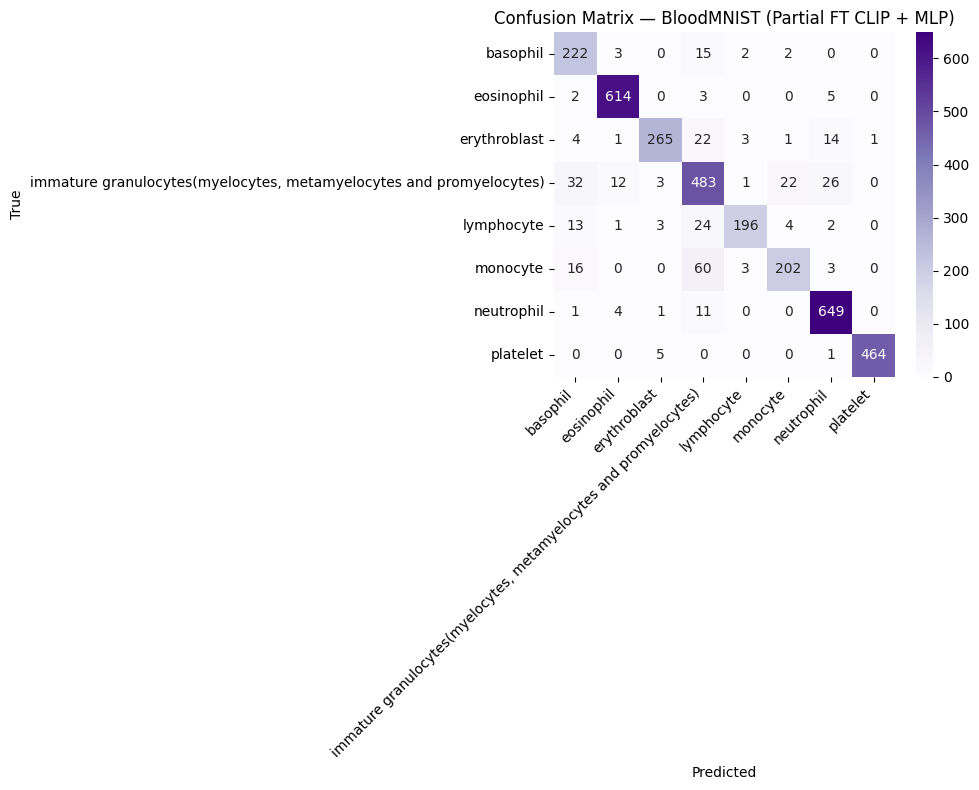

In [16]:
# Confusion Matrix Heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Purples",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.title("Confusion Matrix — BloodMNIST (Partial FT CLIP + MLP)")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig("confusion_matrix_bloodmnist.png", dpi=150)
plt.show()

In [17]:
import json

results = {
    "dataset": "bloodmnist",
    "train_loss": [float(x) for x in train_loss_history],
    "train_acc": [float(x) for x in train_acc_history],
    "val_loss": [float(x) for x in val_loss_history],
    "val_acc": [float(x) for x in val_acc_history],
    "test_acc": float(test_acc),
    "test_f1": float(test_f1),
    "y_true": list(map(int, y_true)),
    "y_pred": list(map(int, y_pred))
}

with open("training_results_bloodmnist.json", "w") as f:
    json.dump(results, f)

print("Saved successfully — training_results_bloodmnist.json")

Saved successfully — training_results_bloodmnist.json


In [18]:
import json
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc, classification_report
from sklearn.preprocessing import label_binarize

# Load saved results
with open("training_results.json", "r") as f:
    path_results = json.load(f)

with open("training_results_bloodmnist.json", "r") as f:
    blood_results = json.load(f)

print("PathMNIST  — Test Acc:", round(path_results["test_acc"], 4))
print("BloodMNIST — Test Acc:", round(blood_results["test_acc"], 4))

PathMNIST  — Test Acc: 0.918
BloodMNIST — Test Acc: 0.9047


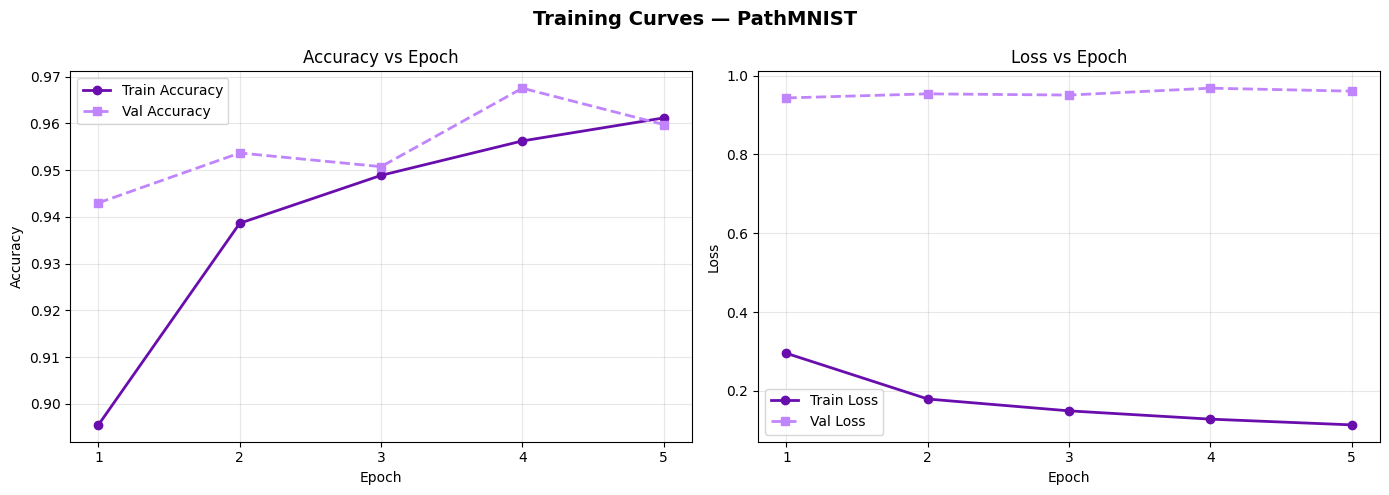

Saved: training_curves_pathmnist.png


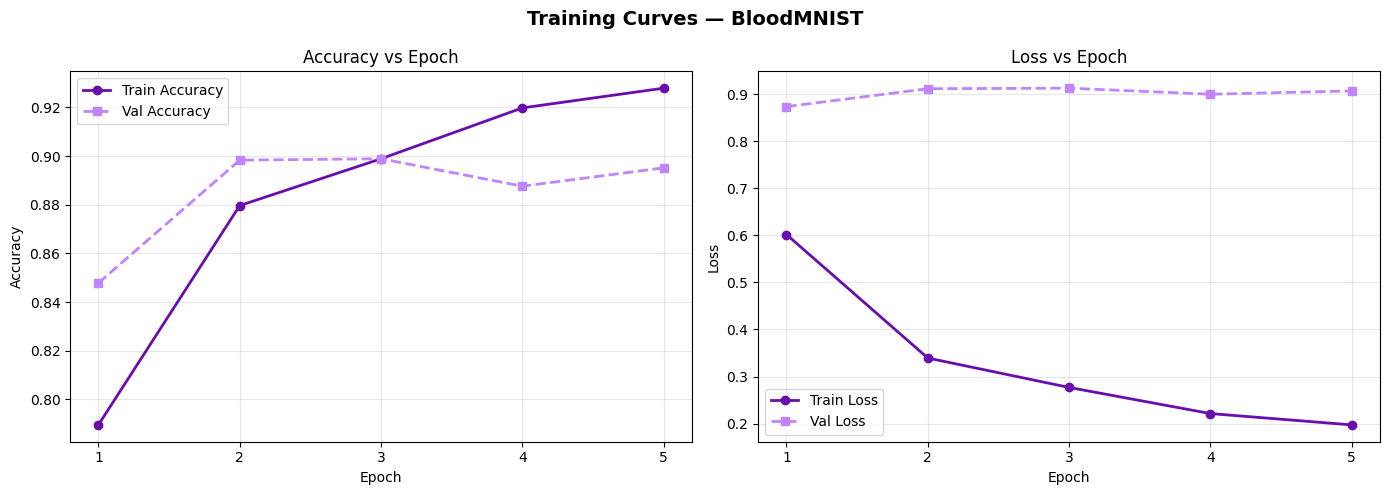

Saved: training_curves_bloodmnist.png


In [19]:
def plot_training_curves(results, dataset_name, save_path):

    epochs = range(1, len(results["train_acc"]) + 1)

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    fig.suptitle(f"Training Curves — {dataset_name}", fontsize=14, fontweight="bold")

    # Accuracy
    axes[0].plot(epochs, results["train_acc"], marker="o", label="Train Accuracy", color="#6a0dad", linewidth=2)
    axes[0].plot(epochs, results["val_acc"], marker="s", label="Val Accuracy", color="#c084fc", linewidth=2, linestyle="--")
    axes[0].set_title("Accuracy vs Epoch")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Accuracy")
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)
    axes[0].set_xticks(epochs)

    # Loss
    axes[1].plot(epochs, results["train_loss"], marker="o", label="Train Loss", color="#6a0dad", linewidth=2)
    axes[1].plot(epochs, results["val_loss"], marker="s", label="Val Loss", color="#c084fc", linewidth=2, linestyle="--")
    axes[1].set_title("Loss vs Epoch")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Loss")
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)
    axes[1].set_xticks(epochs)

    plt.tight_layout()
    plt.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.show()
    print(f"Saved: {save_path}")

# Run for both datasets
plot_training_curves(path_results, "PathMNIST", "training_curves_pathmnist.png")
plot_training_curves(blood_results, "BloodMNIST", "training_curves_bloodmnist.png")

In [21]:
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize

def plot_roc_curves(all_labels, all_probs, class_names, n_classes, dataset_name, save_path):

    labels_bin = label_binarize(all_labels, classes=list(range(n_classes)))

    fpr, tpr, roc_auc = {}, {}, {}

    for i in range(n_classes):
        fpr[i], tpr[i], _ = roc_curve(labels_bin[:, i], all_probs[:, i])
        roc_auc[i] = auc(fpr[i], tpr[i])

    # Macro average
    all_fpr = np.unique(np.concatenate([fpr[i] for i in range(n_classes)]))
    mean_tpr = np.zeros_like(all_fpr)
    for i in range(n_classes):
        mean_tpr += np.interp(all_fpr, fpr[i], tpr[i])
    mean_tpr /= n_classes
    macro_auc = auc(all_fpr, mean_tpr)

    colors = plt.cm.Purples(np.linspace(0.4, 1.0, n_classes))

    fig, ax = plt.subplots(figsize=(10, 8))

    for i, color in zip(range(n_classes), colors):
        ax.plot(fpr[i], tpr[i], color=color, linewidth=1.5,
                label=f"Class {i}: {class_names[i]} (AUC = {roc_auc[i]:.3f})")

    ax.plot(all_fpr, mean_tpr, color="#1a0033", linewidth=2.5, linestyle="--",
            label=f"Macro Average (AUC = {macro_auc:.3f})")

    ax.plot([0, 1], [0, 1], color="gray", linewidth=1, linestyle=":", label="Random Classifier")

    ax.set_xlim([0.0, 1.0])
    ax.set_ylim([0.0, 1.05])
    ax.set_xlabel("False Positive Rate", fontsize=12)
    ax.set_ylabel("True Positive Rate", fontsize=12)
    ax.set_title(f"ROC Curves — {dataset_name}", fontsize=13, fontweight="bold")
    ax.legend(loc="lower right", fontsize=9)
    ax.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.show()
    print(f"Macro AUC: {macro_auc:.4f}")

In [22]:
def evaluate(loader):

    model.eval()

    all_preds = []
    all_labels = []
    all_probs = []      # ← add this

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)
            labels = labels.squeeze().long().to(device)

            outputs = model(images)

            probs = torch.softmax(outputs, dim=1)   # ← add this

            preds = outputs.argmax(1)

            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
            all_probs.extend(probs.cpu().numpy())   # ← add this

    acc = accuracy_score(all_labels, all_preds)
    f1 = f1_score(all_labels, all_preds, average="macro")

    return acc, f1, all_labels, all_preds, np.array(all_probs)  # ← add probs

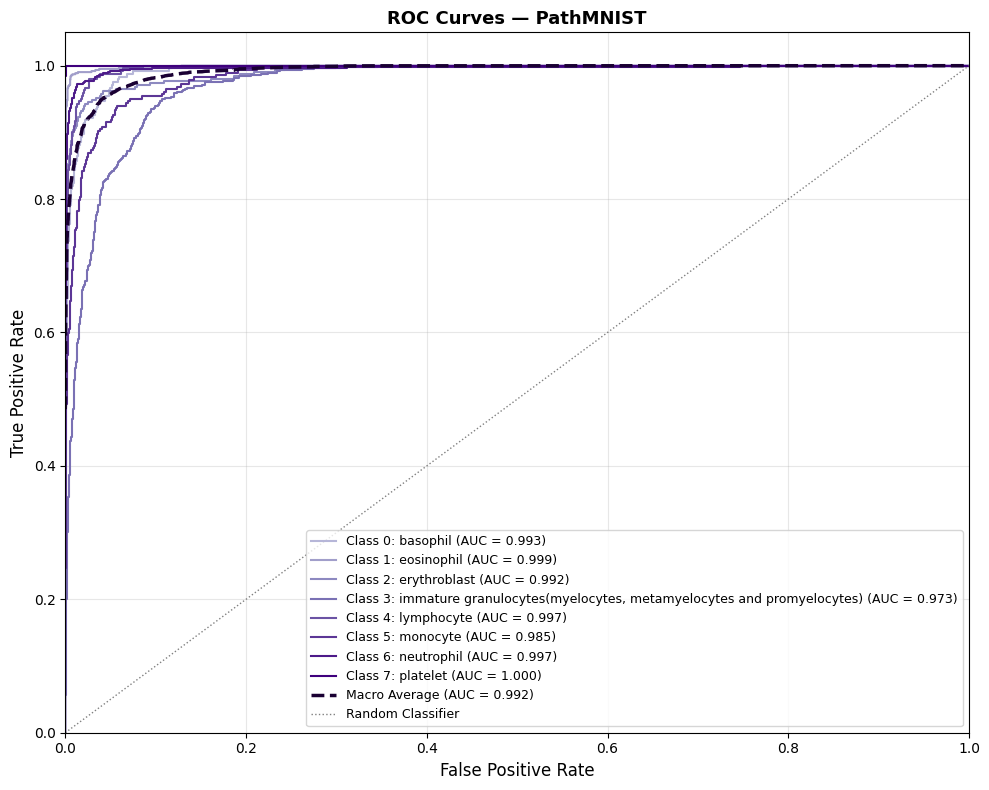

Macro AUC: 0.9921


In [23]:
test_acc, test_f1, y_true, y_pred, y_probs = evaluate(test_loader)

class_names = list(info["label"].values())

plot_roc_curves(y_true, y_probs, class_names, num_classes, "PathMNIST", "roc_pathmnist.png")